# **Deep Learning - Final Project**
## Automatic product-image tagging for an online fashion catalogue

**Author:** Omar Essam  |  **Course:** IBM Deep Learning and Reinforcement Learning

The notebook behind the final report. It trains four deep-learning variations on Zalando's *Fashion-MNIST* product
images - a dense network baseline and three convolutional neural networks (CNNs) of increasing capacity and
regularisation - compares them on one held-out test set, and explains the recommended model: where it errs, how
confident it is, and what its convolution kernels look at. Every figure and table in the report is written to
`figures/` and `results/` from here.

In [1]:
import hashlib
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from sklearn.model_selection import train_test_split
from tensorflow import keras
from tensorflow.keras import layers

warnings.filterwarnings('ignore')
rs = 123
keras.utils.set_random_seed(rs)
FIG, RES = Path('figures'), Path('results')
FIG.mkdir(exist_ok=True)
RES.mkdir(exist_ok=True)

BLUE, ORANGE, GRAY, INK, MUTED, GRID = '#2a78d6', '#eb6834', '#b4b2aa', '#262626', '#898781', '#e1e0d9'
MODEL_COLORS = {'Dense network (MLP)': GRAY, 'Small CNN': '#1baf7a', 'Deep CNN (BatchNorm + Dropout)': ORANGE,
                'Deep CNN + data augmentation': BLUE}
plt.rcParams.update({'font.family': 'Calibri', 'font.size': 14, 'legend.fontsize': 12, 'axes.edgecolor': '#c3c2b7',
                     'axes.labelcolor': INK, 'xtick.color': MUTED, 'ytick.color': MUTED, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.8,
                     'axes.axisbelow': True, 'axes.titlesize': 15, 'axes.titleweight': 'bold', 'axes.titlecolor': INK,
                     'savefig.dpi': 200, 'savefig.bbox': 'tight'})
print('TensorFlow', tf.__version__, '| devices:', [d.device_type for d in tf.config.list_physical_devices()])

TensorFlow 2.17.1 | devices: ['CPU']


## 1. Load and explore the data

In [2]:
(x_train_full, y_train_full), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()
CLASSES = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']
print('train', x_train_full.shape, '| test', x_test.shape, '| dtype', x_train_full.dtype, '| pixel range', x_train_full.min(), '-', x_train_full.max())
print('images per class (train):', dict(zip(CLASSES, np.bincount(y_train_full))))
print('images per class (test):', np.bincount(y_test))

train (60000, 28, 28) | test (10000, 28, 28) | dtype uint8 | pixel range 0 - 255
images per class (train): {'T-shirt/top': 6000, 'Trouser': 6000, 'Pullover': 6000, 'Dress': 6000, 'Coat': 6000, 'Sandal': 6000, 'Shirt': 6000, 'Sneaker': 6000, 'Bag': 6000, 'Ankle boot': 6000}
images per class (test): [1000 1000 1000 1000 1000 1000 1000 1000 1000 1000]


In [3]:
# Data quality: exact duplicate images inside the training set and between training and test
def digest(images):
    return [hashlib.md5(img.tobytes()).hexdigest() for img in images]
train_hash, test_hash = digest(x_train_full), digest(x_test)
dup_train = len(train_hash) - len(set(train_hash))
leak = len(set(train_hash) & set(test_hash))
mean_by_class = pd.Series([x_train_full[y_train_full == c].mean() for c in range(10)], index=CLASSES)
print(f'duplicate images within train: {dup_train}; test images also present in train: {leak}')
print('mean pixel intensity by class (0-255):')
mean_by_class.round(1)

duplicate images within train: 0; test images also present in train: 0
mean pixel intensity by class (0-255):


T-shirt/top    83.0
Trouser        56.8
Pullover       96.1
Dress          66.0
Coat           98.3
Sandal         34.9
Shirt          84.6
Sneaker        42.8
Bag            90.2
Ankle boot     76.8
dtype: float64

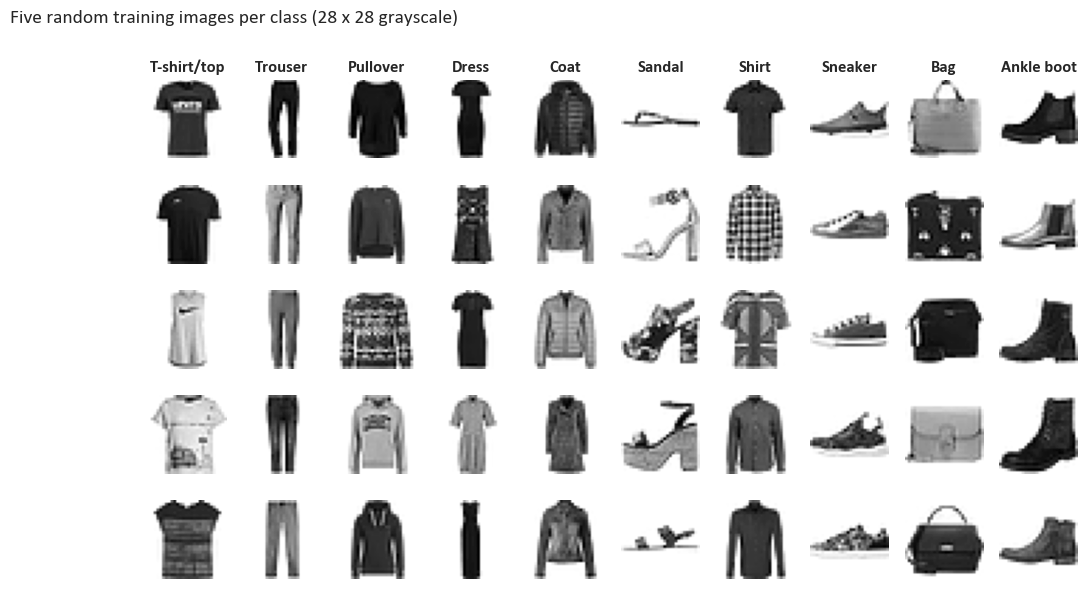

In [4]:
fig, axes = plt.subplots(5, 10, figsize=(12, 6.6))
rng = np.random.default_rng(rs)
for c in range(10):
    idx = rng.choice(np.where(y_train_full == c)[0], 5, replace=False)
    for r, i in enumerate(idx):
        ax = axes[r, c]
        ax.imshow(x_train_full[i], cmap='gray_r')
        ax.set_xticks([])
        ax.set_yticks([])
        ax.grid(False)
        for s in ax.spines.values():
            s.set_visible(False)
        if r == 0:
            ax.set_title(CLASSES[c], fontsize=12, fontweight='bold')
plt.suptitle('Five random training images per class (28 x 28 grayscale)', x=0.01, ha='left', fontsize=14, color=INK)
plt.savefig(FIG / 'fig1_samples.png')
plt.show()

## 2. Preparation

* Pixels are scaled from 0-255 to 0-1 and given a channel dimension (28 x 28 x 1).
* The 60,000 training images are split, stratified by class, into 54,000 for training and 6,000 for validation
  (early stopping and learning-rate decisions); the official 10,000 test images are only used for the final comparison.
* Data augmentation (variation 4) adds random horizontal flips, shifts and zooms during training only.

In [5]:
x_all = (x_train_full.astype('float32') / 255.0)[..., None]
x_test_s = (x_test.astype('float32') / 255.0)[..., None]
x_tr, x_val, y_tr, y_val = train_test_split(x_all, y_train_full, test_size=6000, stratify=y_train_full, random_state=rs)
print('train', x_tr.shape, 'validation', x_val.shape, 'test', x_test_s.shape)

train (54000, 28, 28, 1) validation (6000, 28, 28, 1) test (10000, 28, 28, 1)


## 3. Four model variations

| Variation | Idea |
|---|---|
| Dense network (MLP) | baseline without convolutions: every pixel is an independent input |
| Small CNN | two convolution + max-pooling blocks learn local patterns (edges, textures) |
| Deep CNN (BatchNorm + Dropout) | three VGG-style blocks, batch normalisation and dropout against overfitting |
| Deep CNN + data augmentation | the same network trained on randomly flipped, shifted and zoomed images |

All use Adam (learning rate 0.001), batch size 128, early stopping on validation loss (patience 5, best weights
restored) and halving of the learning rate when validation loss plateaus.

In [6]:
def dense_mlp():
    return keras.Sequential([layers.Input((28, 28, 1)), layers.Flatten(), layers.Dense(256, activation='relu'), layers.Dropout(0.3),
                             layers.Dense(128, activation='relu'), layers.Dropout(0.3), layers.Dense(10, activation='softmax')], name='mlp')

def small_cnn():
    return keras.Sequential([layers.Input((28, 28, 1)),
                             layers.Conv2D(32, 3, activation='relu', padding='same', name='conv1'), layers.MaxPooling2D(),
                             layers.Conv2D(64, 3, activation='relu', padding='same', name='conv2'), layers.MaxPooling2D(),
                             layers.Flatten(), layers.Dense(128, activation='relu'), layers.Dropout(0.3),
                             layers.Dense(10, activation='softmax')], name='small_cnn')

def deep_cnn(augment=False):
    aug = [layers.RandomFlip('horizontal'), layers.RandomTranslation(0.08, 0.08), layers.RandomZoom(0.08)] if augment else []
    def block(filters, n, name):
        out = []
        for i in range(n):
            out += [layers.Conv2D(filters, 3, padding='same', use_bias=False, name=f'{name}_conv{i + 1}'), layers.BatchNormalization(),
                    layers.Activation('relu')]
        return out + [layers.MaxPooling2D(), layers.Dropout(0.25)]
    return keras.Sequential([layers.Input((28, 28, 1)), *aug, *block(32, 2, 'b1'), *block(64, 2, 'b2'), *block(128, 1, 'b3'),
                             layers.Flatten(), layers.Dense(128, activation='relu'), layers.Dropout(0.4),
                             layers.Dense(10, activation='softmax')], name='deep_cnn_aug' if augment else 'deep_cnn')

variations = {'Dense network (MLP)': (dense_mlp, 40), 'Small CNN': (small_cnn, 30),
              'Deep CNN (BatchNorm + Dropout)': (lambda: deep_cnn(False), 30), 'Deep CNN + data augmentation': (lambda: deep_cnn(True), 40)}

In [7]:
models, histories, rows = {}, [], []
for name, (build, max_epochs) in variations.items():
    keras.utils.set_random_seed(rs)
    model = build()
    model.compile(optimizer=keras.optimizers.Adam(1e-3), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    callbacks = [keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True),
                 keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-5)]
    start = time.time()
    hist = model.fit(x_tr, y_tr, validation_data=(x_val, y_val), epochs=max_epochs, batch_size=128, callbacks=callbacks, verbose=0)
    train_seconds = time.time() - start
    h = pd.DataFrame(hist.history)
    h['epoch'] = np.arange(1, len(h) + 1)
    h['model'] = name
    histories.append(h)
    start = time.time()
    proba = model.predict(x_test_s, batch_size=512, verbose=0)
    infer_ms = (time.time() - start) / len(x_test_s) * 1000
    pred = proba.argmax(1)
    _, train_acc = model.evaluate(x_tr, y_tr, batch_size=512, verbose=0)
    val_loss, val_acc = model.evaluate(x_val, y_val, batch_size=512, verbose=0)
    test_loss, test_acc = model.evaluate(x_test_s, y_test, batch_size=512, verbose=0)
    best_epoch = int(h['val_loss'].idxmin() + 1)
    rows.append({'model': name, 'parameters': model.count_params(), 'epochs_run': len(h), 'best_epoch': best_epoch,
                 'train_minutes': train_seconds / 60, 'train_acc': train_acc, 'val_acc': val_acc, 'test_acc': test_acc,
                 'test_loss': test_loss, 'test_f1_macro': f1_score(y_test, pred, average='macro'), 'infer_ms_per_image': infer_ms})
    models[name] = (model, proba)
    print(f'{name:34s} test acc {test_acc:.4f}  train acc {train_acc:.4f}  epochs {len(h)}  {train_seconds / 60:.1f} min')
comparison = pd.DataFrame(rows)
comparison.to_csv(RES / 'model_comparison.csv', index=False)
history = pd.concat(histories)
history.to_csv(RES / 'training_history.csv', index=False)
comparison.round(4)

Dense network (MLP)                test acc 0.8930  train acc 0.9294  epochs 27  1.0 min


Small CNN                          test acc 0.9161  train acc 0.9473  epochs 14  2.2 min


Deep CNN (BatchNorm + Dropout)     test acc 0.9367  train acc 0.9636  epochs 27  23.5 min


Deep CNN + data augmentation       test acc 0.9263  train acc 0.9395  epochs 40  32.8 min


,model,parameters,epochs_run,best_epoch,train_minutes,train_acc,val_acc,test_acc,test_loss,test_f1_macro,infer_ms_per_image
0,Dense network (MLP),235146,27,22,0.9574,0.9294,0.8987,0.8930,0.3140,0.8926,0.0256
1,Small CNN,421642,14,9,2.1716,0.9473,0.9195,0.9161,0.2376,0.9161,0.0628
2,Deep CNN (BatchNorm + Dropout),288682,27,22,23.5003,0.9636,0.9397,0.9367,0.1791,0.9366,0.2167
3,Deep CNN + data augmentation,288682,40,38,32.7969,0.9395,0.9317,0.9263,0.2017,0.9262,0.2064


### Test-set uncertainty

A 95% bootstrap interval for each model's test accuracy, and for the accuracy difference between the two strongest
models, shows whether the ranking is meaningful.

In [8]:
rng = np.random.default_rng(rs)
boot = [rng.integers(0, len(y_test), len(y_test)) for _ in range(1000)]
correct = {name: (proba.argmax(1) == y_test) for name, (_, proba) in models.items()}
ci = {name: np.percentile([c[b].mean() for b in boot], [2.5, 97.5]) for name, c in correct.items()}
comparison['acc_ci_low'] = [ci[n][0] for n in comparison['model']]
comparison['acc_ci_high'] = [ci[n][1] for n in comparison['model']]
ranked = comparison.sort_values('test_acc', ascending=False)['model'].tolist()
best_name, second = ranked[0], ranked[1]
diff = [correct[best_name][b].mean() - correct[second][b].mean() for b in boot]
comparison['diff_vs_second'] = ''
comparison.loc[comparison['model'] == best_name, 'diff_vs_second'] = f'{np.percentile(diff, 2.5):+.4f} to {np.percentile(diff, 97.5):+.4f}'
comparison.to_csv(RES / 'model_comparison.csv', index=False)
print('best:', best_name, '| runner-up:', second, '| 95% interval of the accuracy difference:', comparison.loc[comparison['model'] == best_name, 'diff_vs_second'].iloc[0])
comparison[['model', 'test_acc', 'acc_ci_low', 'acc_ci_high']].round(4)

best: Deep CNN (BatchNorm + Dropout) | runner-up: Deep CNN + data augmentation | 95% interval of the accuracy difference: +0.0063 to +0.0147


,model,test_acc,acc_ci_low,acc_ci_high
0,Dense network (MLP),0.8930,0.8868,0.8989
1,Small CNN,0.9161,0.9104,0.9216
2,Deep CNN (BatchNorm + Dropout),0.9367,0.9320,0.9414
3,Deep CNN + data augmentation,0.9263,0.9211,0.9313


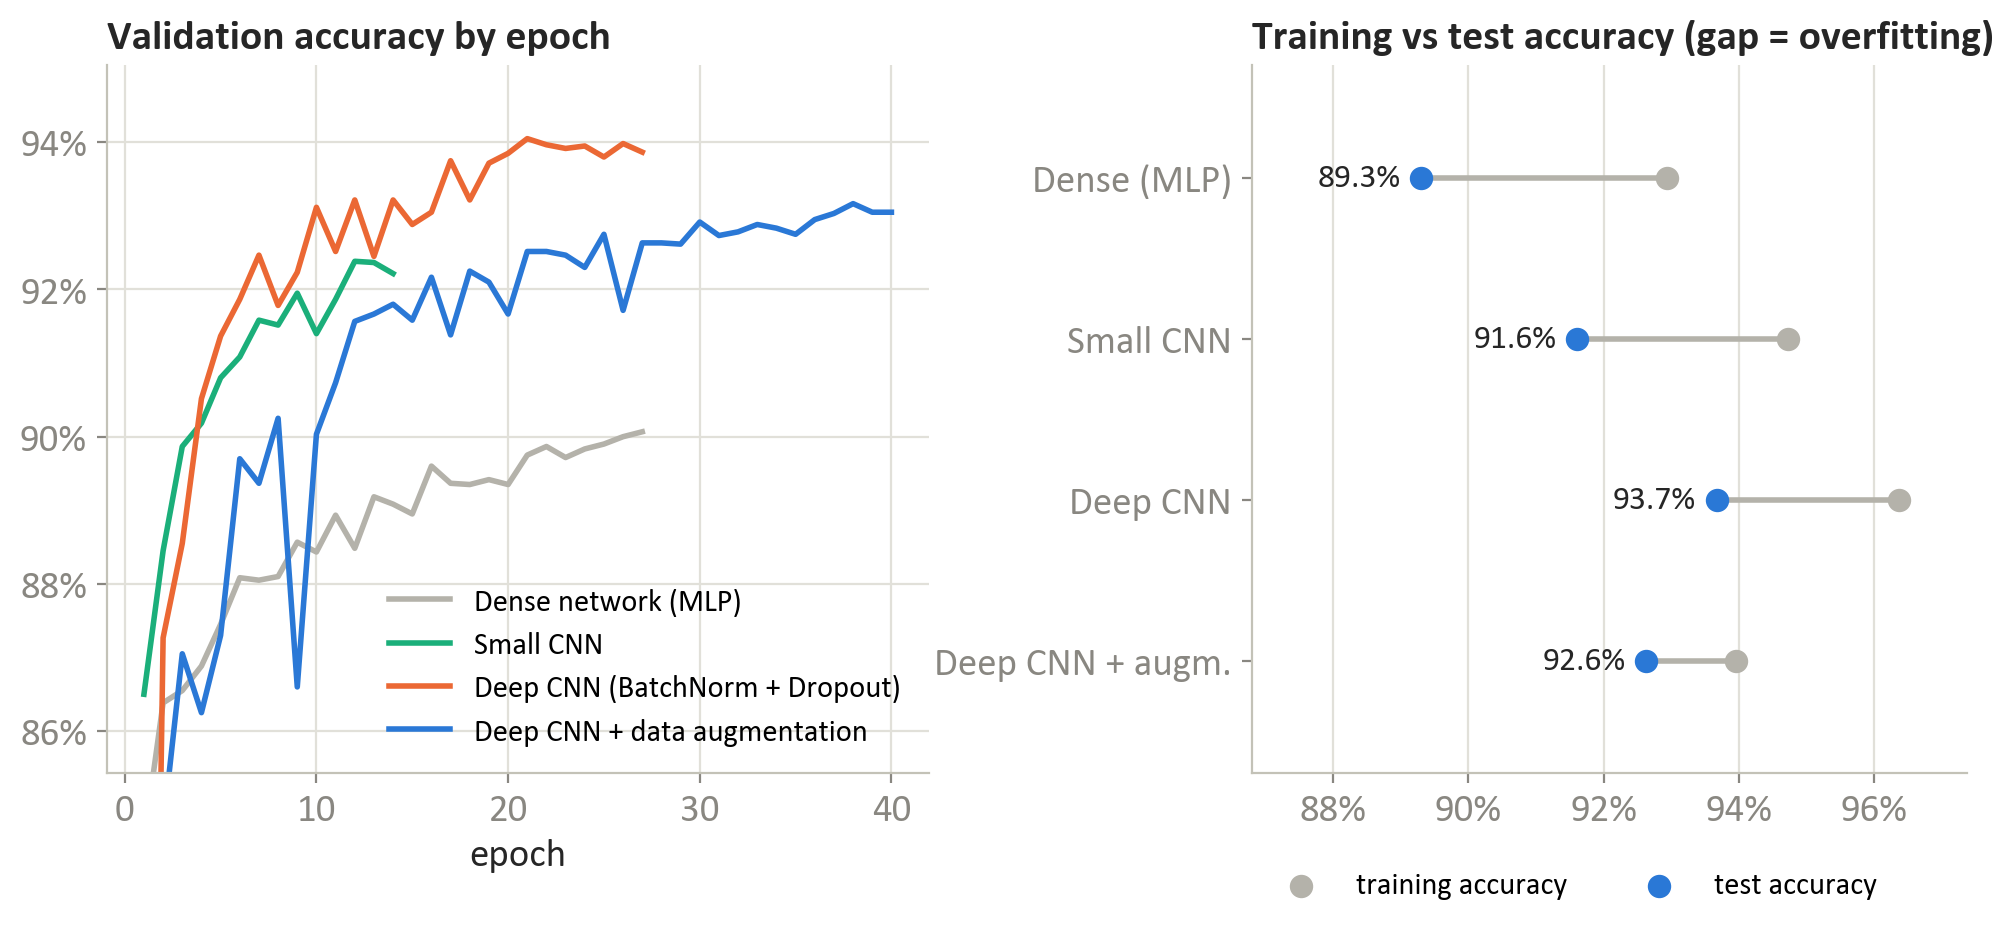

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), gridspec_kw={'wspace': 0.42, 'width_ratios': [1.15, 1]})
for name, h in history.groupby('model', sort=False):
    axes[0].plot(h['epoch'], h['val_accuracy'], '-', color=MODEL_COLORS[name], linewidth=2, label=name)
axes[0].set_title('Validation accuracy by epoch', loc='left')
axes[0].set_xlabel('epoch')
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
axes[0].set_ylim(max(0.0, history['val_accuracy'].quantile(0.05) - 0.01), min(1.0, history['val_accuracy'].max() + 0.01))
axes[0].legend(frameon=False, fontsize=11, loc='lower right')
order = comparison.iloc[::-1]
y = np.arange(len(order))
axes[1].hlines(y, order['test_acc'], order['train_acc'], color=GRAY, linewidth=2)
axes[1].scatter(order['train_acc'], y, color=GRAY, s=55, zorder=3, label='training accuracy')
axes[1].scatter(order['test_acc'], y, color=BLUE, s=55, zorder=3, label='test accuracy')
for yi, (tr, te) in enumerate(zip(order['train_acc'], order['test_acc'])):
    axes[1].text(min(tr, te) - 0.003, yi, f'{te:.1%}', va='center', ha='right', fontsize=12, color=INK, clip_on=True)
SHORT = {'Dense network (MLP)': 'Dense (MLP)', 'Small CNN': 'Small CNN', 'Deep CNN (BatchNorm + Dropout)': 'Deep CNN',
         'Deep CNN + data augmentation': 'Deep CNN + augm.'}
axes[1].set_yticks(y, [SHORT[n] for n in order['model']])
axes[1].xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
lo = min(order['test_acc'].min(), order['train_acc'].min())
axes[1].set_xlim(max(0.0, lo - 0.025), min(1.0, max(order['test_acc'].max(), order['train_acc'].max()) + 0.01))
axes[1].set_ylim(-0.7, len(order) - 0.3)
axes[1].set_title('Training vs test accuracy (gap = overfitting)', loc='left')
axes[1].legend(frameon=False, fontsize=11, loc='upper center', bbox_to_anchor=(0.45, -0.1), ncol=2)
axes[1].grid(axis='y', visible=False)
plt.savefig(FIG / 'fig2_training_comparison.png')
plt.show()

## 4. Explain the recommended model

In [10]:
final_name = best_name
final_model, final_proba = models[final_name]
final_pred = final_proba.argmax(1)
report = pd.DataFrame(classification_report(y_test, final_pred, target_names=CLASSES, output_dict=True)).T.iloc[:10]
report.to_csv(RES / 'per_class.csv', index_label='class')
cm = confusion_matrix(y_test, final_pred)
pd.DataFrame(cm, index=CLASSES, columns=CLASSES).to_csv(RES / 'confusion_matrix.csv')
pairs = [(CLASSES[i], CLASSES[j], cm[i, j]) for i in range(10) for j in range(10) if i != j]
top_conf = pd.DataFrame(sorted(pairs, key=lambda p: -p[2])[:8], columns=['true', 'predicted', 'count'])
top_conf.to_csv(RES / 'top_confusions.csv', index=False)
print(final_name)
report.round(3)

Deep CNN (BatchNorm + Dropout)


,precision,recall,f1-score,support
T-shirt/top,0.897,0.893,0.895,1000.0
Trouser,0.997,0.986,0.991,1000.0
Pullover,0.915,0.907,0.911,1000.0
Dress,0.927,0.941,0.934,1000.0
Coat,0.884,0.923,0.903,1000.0
Sandal,0.991,0.985,0.988,1000.0
Shirt,0.820,0.793,0.806,1000.0
Sneaker,0.965,0.979,0.972,1000.0
Bag,0.994,0.990,0.992,1000.0
Ankle boot,0.976,0.970,0.973,1000.0


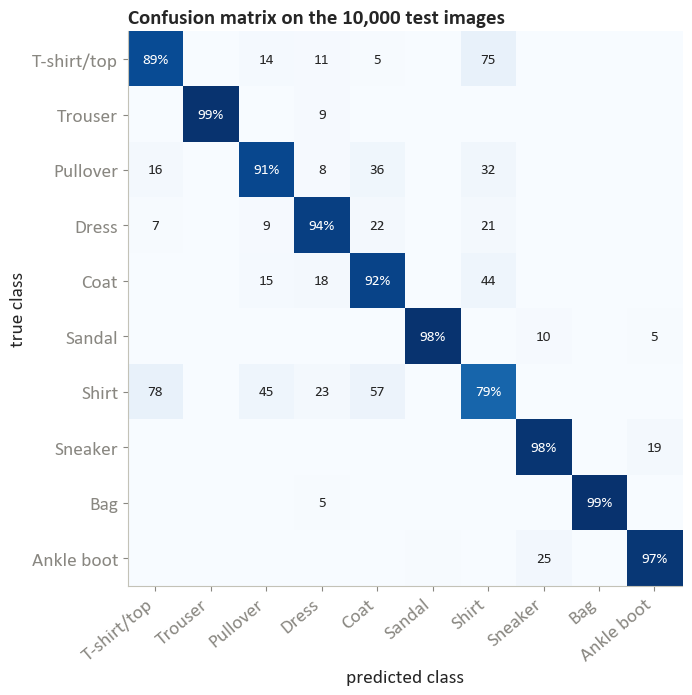

,true,predicted,count
0,Shirt,T-shirt/top,78
1,T-shirt/top,Shirt,75
2,Shirt,Coat,57
3,Shirt,Pullover,45
4,Coat,Shirt,44
5,Pullover,Coat,36
6,Pullover,Shirt,32
7,Ankle boot,Sneaker,25


In [11]:
fig, ax = plt.subplots(figsize=(8.8, 7.2))
cmn = cm / cm.sum(axis=1, keepdims=True)
im = ax.imshow(cmn, cmap='Blues', vmin=0, vmax=1)
for i in range(10):
    for j in range(10):
        if cm[i, j] >= 5 or i == j:
            ax.text(j, i, f'{cmn[i, j]:.0%}' if i == j else str(cm[i, j]), ha='center', va='center', fontsize=11,
                    color='white' if cmn[i, j] > 0.6 else INK)
ax.set_xticks(range(10), CLASSES, rotation=40, ha='right')
ax.set_yticks(range(10), CLASSES)
ax.set_xlabel('predicted class')
ax.set_ylabel('true class')
ax.grid(False)
ax.set_title('Confusion matrix on the 10,000 test images', loc='left')
plt.savefig(FIG / 'fig3_confusion_matrix.png')
plt.show()
top_conf

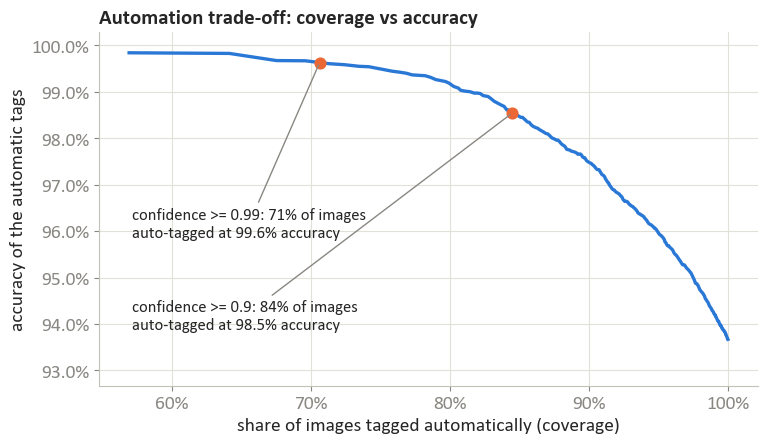

,threshold,coverage,accuracy,error_rate,sent_to_review
0,0.00,1.0000,0.9367,0.0633,0.0000
1,0.50,0.9878,0.9434,0.0566,0.0122
2,0.70,0.9276,0.9664,0.0336,0.0724
3,0.80,0.8942,0.9765,0.0235,0.1058
4,0.90,0.8448,0.9854,0.0146,0.1552
5,0.95,0.8013,0.9914,0.0086,0.1987
6,0.98,0.7463,0.9952,0.0048,0.2537
7,0.99,0.7063,0.9963,0.0037,0.2937


In [12]:
# Business view: auto-accept only confident predictions and send the rest to a human tagger
conf = final_proba.max(1)
ok = final_pred == y_test
rows = []
for t in [0.0, 0.5, 0.7, 0.8, 0.9, 0.95, 0.98, 0.99]:
    keep = conf >= t
    rows.append({'threshold': t, 'coverage': keep.mean(), 'accuracy': ok[keep].mean(), 'error_rate': 1 - ok[keep].mean(),
                 'sent_to_review': 1 - keep.mean()})
coverage = pd.DataFrame(rows)
coverage.to_csv(RES / 'coverage_accuracy.csv', index=False)
ts = np.linspace(0, 0.999, 400)
cov = np.array([(conf >= t).mean() for t in ts])
acc = np.array([ok[conf >= t].mean() for t in ts])
fig, ax = plt.subplots(figsize=(8.5, 4.6))
ax.plot(cov, acc, color=BLUE, linewidth=2.4)
for t in (0.9, 0.99):
    r = coverage[coverage['threshold'] == t].iloc[0]
    ax.scatter([r['coverage']], [r['accuracy']], color=ORANGE, s=60, zorder=3)
    ax.annotate(f"confidence >= {t:g}: {r['coverage']:.0%} of images\nauto-tagged at {r['accuracy']:.1%} accuracy",
                (r['coverage'], r['accuracy']), xytext=(0.05, 0.42 if t == 0.99 else 0.16), textcoords='axes fraction',
                ha='left', fontsize=12, color=INK, arrowprops=dict(arrowstyle='-', color=MUTED))
ax.set_xlabel('share of images tagged automatically (coverage)')
ax.set_ylabel('accuracy of the automatic tags')
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.1%}'))
ax.set_ylim(max(0.0, acc.min() - 0.01), 1.003)
ax.set_title('Automation trade-off: coverage vs accuracy', loc='left')
plt.savefig(FIG / 'fig4_coverage_accuracy.png')
plt.show()
coverage.round(4)

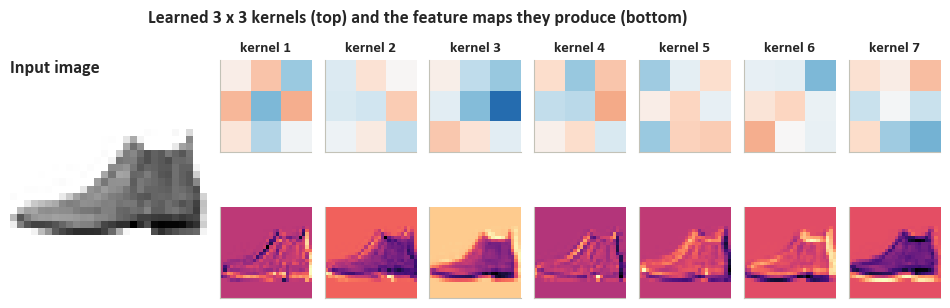

first conv layer kernels: (3, 3, 1, 32)


In [13]:
# What the convolution kernels learn: first-layer 3x3 kernels and their feature maps for one image
def tap(model, layer):
    # functional view of a trained Sequential model: outputs of `layer` and of the whole network (same weights)
    inp = keras.Input((28, 28, 1))
    x, tapped = inp, None
    for l in model.layers:
        x = l(x)
        if l is layer:
            tapped = x
    return keras.Model(inp, [tapped, x])

conv_layers = [l for l in final_model.layers if isinstance(l, layers.Conv2D)]
first = conv_layers[0]
kernels = first.get_weights()[0][:, :, 0, :]  # 3 x 3 x filters
sample_idx = int(np.where((y_test == CLASSES.index('Ankle boot')) & ok)[0][0])
first_tap = tap(final_model, first)
feature_model = keras.Model(first_tap.input, first_tap.outputs[0])
maps = feature_model.predict(x_test_s[sample_idx:sample_idx + 1], verbose=0)[0]
fig = plt.figure(figsize=(12, 3.6))
gs = fig.add_gridspec(2, 9, wspace=0.15, hspace=0.12)
ax = fig.add_subplot(gs[:, :2])
ax.imshow(x_test_s[sample_idx, :, :, 0], cmap='gray_r')
ax.set_title('Input image', loc='left', fontsize=13)
ax.axis('off')
for k in range(7):
    a = fig.add_subplot(gs[0, k + 2])
    a.imshow(kernels[:, :, k], cmap='RdBu_r', vmin=-np.abs(kernels).max(), vmax=np.abs(kernels).max())
    a.set_xticks([]); a.set_yticks([]); a.grid(False)
    a.set_title(f'kernel {k + 1}', fontsize=11)
    b = fig.add_subplot(gs[1, k + 2])
    b.imshow(maps[:, :, k], cmap='magma')
    b.set_xticks([]); b.set_yticks([]); b.grid(False)
fig.text(0.24, 0.93, 'Learned 3 x 3 kernels (top) and the feature maps they produce (bottom)', fontsize=13, fontweight='bold', color=INK)
plt.savefig(FIG / 'fig5_kernels_feature_maps.png')
plt.show()
print('first conv layer kernels:', first.get_weights()[0].shape)

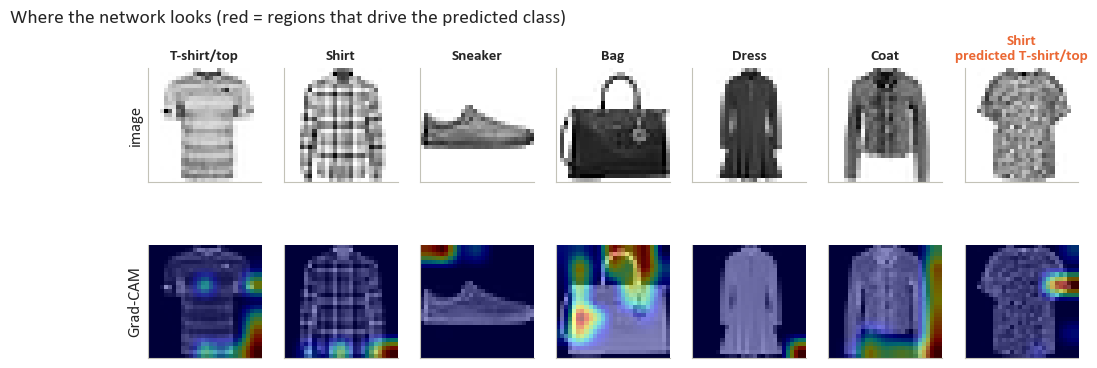

In [14]:
# Grad-CAM: which parts of the image drive the prediction
last_conv = conv_layers[-1]
grad_model = tap(final_model, last_conv)

def grad_cam(image, class_index):
    with tf.GradientTape() as tape:
        conv_out, preds = grad_model(image[None, ...], training=False)
        score = preds[:, class_index]
    grads = tape.gradient(score, conv_out)[0]
    weights = tf.reduce_mean(grads, axis=(0, 1))
    cam = tf.nn.relu(tf.reduce_sum(conv_out[0] * weights, axis=-1)).numpy()
    cam = tf.image.resize(cam[..., None], (28, 28)).numpy()[..., 0]
    return cam / (cam.max() + 1e-9)

show = []
for cls in ['T-shirt/top', 'Shirt', 'Sneaker', 'Bag', 'Dress', 'Coat']:
    c = CLASSES.index(cls)
    show.append(int(np.where((y_test == c) & ok)[0][1]))
wrong = np.where((y_test == CLASSES.index('Shirt')) & (final_pred == CLASSES.index('T-shirt/top')))[0]
if len(wrong):
    show.append(int(wrong[0]))
fig, axes = plt.subplots(2, len(show), figsize=(12, 4.2))
for j, i in enumerate(show):
    cam = grad_cam(x_test_s[i], int(final_pred[i]))
    axes[0, j].imshow(x_test_s[i, :, :, 0], cmap='gray_r')
    axes[1, j].imshow(x_test_s[i, :, :, 0], cmap='gray')
    axes[1, j].imshow(cam, cmap='jet', alpha=0.45)
    label = f'{CLASSES[y_test[i]]}' if final_pred[i] == y_test[i] else f'{CLASSES[y_test[i]]}\npredicted {CLASSES[final_pred[i]]}'
    axes[0, j].set_title(label, fontsize=11, color=INK if final_pred[i] == y_test[i] else ORANGE)
    for a in axes[:, j]:
        a.set_xticks([]); a.set_yticks([]); a.grid(False)
axes[0, 0].set_ylabel('image', fontsize=12)
axes[1, 0].set_ylabel('Grad-CAM', fontsize=12)
plt.suptitle('Where the network looks (red = regions that drive the predicted class)', x=0.01, ha='left', fontsize=14, color=INK)
plt.savefig(FIG / 'fig6_gradcam.png')
plt.show()

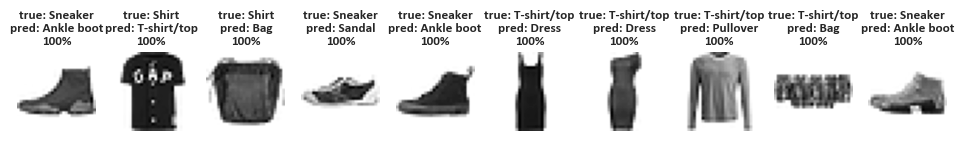

633 test mistakes; 19% of them made with confidence >= 0.9


In [15]:
# The hardest cases: the most confident mistakes
mistakes = np.where(~ok)[0]
worst = mistakes[np.argsort(-conf[mistakes])][:10]
fig, axes = plt.subplots(1, 10, figsize=(12, 2.4))
for a, i in zip(axes, worst):
    a.imshow(x_test_s[i, :, :, 0], cmap='gray_r')
    a.set_title(f'true: {CLASSES[y_test[i]]}\npred: {CLASSES[final_pred[i]]}\n{conf[i]:.0%}', fontsize=9.5, color=INK)
    a.axis('off')
plt.savefig(FIG / 'fig7_confident_mistakes.png')
plt.show()
print(f'{(~ok).sum()} test mistakes; {np.mean(conf[~ok] >= 0.9):.0%} of them made with confidence >= 0.9')

In [16]:
summary = {
    'train_images': len(x_tr), 'val_images': len(x_val), 'test_images': len(x_test), 'classes': 10,
    'duplicates_in_train': dup_train, 'test_in_train': leak, 'final_model': final_name,
    'mistakes': int((~ok).sum()), 'confident_mistake_share': float(np.mean(conf[~ok] >= 0.9)),
    'shirt_recall': float(report.loc['Shirt', 'recall']), 'mean_pixel_darkest_class': mean_by_class.idxmax(),
}
pd.Series(summary).to_csv(RES / 'summary.csv', header=['value'], index_label='metric')
pd.Series(summary)

train_images                                         54000
val_images                                            6000
test_images                                          10000
classes                                                 10
duplicates_in_train                                      0
test_in_train                                            0
final_model                 Deep CNN (BatchNorm + Dropout)
mistakes                                               633
confident_mistake_share                           0.194313
shirt_recall                                         0.793
mean_pixel_darkest_class                              Coat
dtype: object

In [17]:
# Report layout: a two-row version of the confident-mistakes figure (cut at the white gap between images 5 and 6)
from PIL import Image

strip = Image.open(FIG / 'fig7_confident_mistakes.png').convert('RGB')
pixels = np.asarray(strip).astype(int)
white = (pixels.min(axis=2) > 245).all(axis=0)
mid = strip.width // 2
cols = [x for x in range(int(strip.width * 0.4), int(strip.width * 0.6)) if white[x]]
runs, start = [], cols[0]
for a, b in zip(cols, cols[1:] + [None]):
    if b != a + 1:
        runs.append((start, a))
        start = b
gap = min(runs, key=lambda r: abs((r[0] + r[1]) / 2 - mid))
cut = (gap[0] + gap[1]) // 2
left, right = strip.crop((0, 0, cut, strip.height)), strip.crop((cut, 0, strip.width, strip.height))
width = max(left.width, right.width)
two_rows = Image.new('RGB', (width, 2 * strip.height + 30), 'white')
two_rows.paste(left, ((width - left.width) // 2, 0))
two_rows.paste(right, ((width - right.width) // 2, strip.height + 30))
two_rows.save(FIG / 'fig7_confident_mistakes_2rows.png', dpi=(200, 200))
print('cut at column', cut, '->', two_rows.size)

cut at column 964 -> (964, 604)
